In [1]:
!pip install scikit-learn-extra


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install scikit-fuzzy


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
!pip install networkx


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
!pip install numpy==1.26.4


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Dataset Description

The dataset used in this project is a Heart Disease Risk Dataset containing 4,238 records and 16 features after preprocessing. It includes both numerical and categorical attributes describing patients’ demographic information, lifestyle habits, and clinical measurements.

The dataset contains key health-related variables such as age, gender, cholesterol levels, blood pressure, BMI, smoking behavior, diabetes status, and heart rate. These features collectively represent important risk factors associated with cardiovascular diseases.

A target variable was derived to indicate the presence or absence of heart stroke, allowing supervised interpretation alongside unsupervised learning methods.

The dataset was obtained from [Kaggle]

## Domain Motivation

Cardiovascular diseases are among the leading causes of death worldwide, and early detection of risk factors can significantly reduce mortality rates. This makes heart disease prediction a critical problem in healthcare analytics.

The motivation behind selecting this dataset is to explore how machine learning and data mining techniques can be used to:

Identify hidden patterns in patient health data
Segment individuals into meaningful risk groups using clustering
Build interpretable decision-making systems using fuzzy logic
Optimize model parameters using genetic algorithms for improved performance

By combining multiple data mining techniques, the project aims to simulate a real-world intelligent healthcare decision support system that can assist in early risk identification and preventive healthcare planning.

In [5]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import random

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score


import skfuzzy as fuzz
from skfuzzy import control as ctrl

import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering


import warnings
warnings.filterwarnings('ignore')

In [6]:
df = pd.read_csv(r"C:\Users\A T G\Downloads\heart_disease (1).csv")
df.head()

,Gender,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,Heart_ stroke
0,Male,39,postgraduate,0,0.0,0.0,no,0,0,195.0,106.0,70.0,26.97,80.0,77.0,No
1,Female,46,primaryschool,0,0.0,0.0,no,0,0,250.0,121.0,81.0,28.73,95.0,76.0,No
2,Male,48,uneducated,1,20.0,0.0,no,0,0,245.0,127.5,80.0,25.34,75.0,70.0,No
3,Female,61,graduate,1,30.0,0.0,no,1,0,225.0,150.0,95.0,28.58,65.0,103.0,yes
4,Female,46,graduate,1,23.0,0.0,no,0,0,285.0,130.0,84.0,23.10,85.0,85.0,No


In [7]:
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Gender           4238 non-null   str    
 1   age              4238 non-null   int64  
 2   education        4133 non-null   str    
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   str    
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  Heart_ stroke    4238 non-null   str    
dtypes: float64(8), int64(4), str(4)
memory usage: 529.9 KB


(4238, 16)

In [8]:
df.describe()


,age,currentSmoker,cigsPerDay,BPMeds,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose
count,4238.000000,4238.000000,4209.000000,4185.000000,4238.000000,4238.000000,4188.000000,4238.000000,4238.000000,4219.000000,4237.000000,3850.000000
mean,49.584946,0.494101,9.003089,0.029630,0.310524,0.025720,236.721585,132.352407,82.893464,25.802008,75.878924,81.966753
std,8.572160,0.500024,11.920094,0.169584,0.462763,0.158316,44.590334,22.038097,11.910850,4.080111,12.026596,23.959998
min,32.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000
25%,42.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000
50%,49.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000
75%,56.000000,1.000000,20.000000,0.000000,1.000000,0.000000,263.000000,144.000000,89.875000,28.040000,83.000000,87.000000
max,70.000000,1.000000,70.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000


In [9]:
missing_values = df.isnull().sum()
print(missing_values)

Gender               0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
Heart_ stroke        0
dtype: int64


In [10]:
corr = df.corr(numeric_only=True)
print(corr)

                    age  currentSmoker  cigsPerDay    BPMeds  prevalentHyp  \
age            1.000000      -0.213748   -0.192791  0.122995      0.307194   
currentSmoker -0.213748       1.000000    0.769690 -0.048938     -0.103260   
cigsPerDay    -0.192791       0.769690    1.000000 -0.046134     -0.066146   
BPMeds         0.122995      -0.048938   -0.046134  1.000000      0.261187   
prevalentHyp   0.307194      -0.103260   -0.066146  0.261187      1.000000   
diabetes       0.101258      -0.044295   -0.037067  0.052047      0.077808   
totChol        0.262131      -0.046562   -0.026320  0.080558      0.163993   
sysBP          0.394302      -0.130230   -0.088780  0.254219      0.696755   
diaBP          0.206104      -0.107746   -0.056632  0.194227      0.615751   
BMI            0.135800      -0.167650   -0.092856  0.100668      0.301318   
heartRate     -0.012823       0.062356    0.075157  0.015233      0.147261   
glucose        0.122256      -0.056826   -0.058960  0.051176    

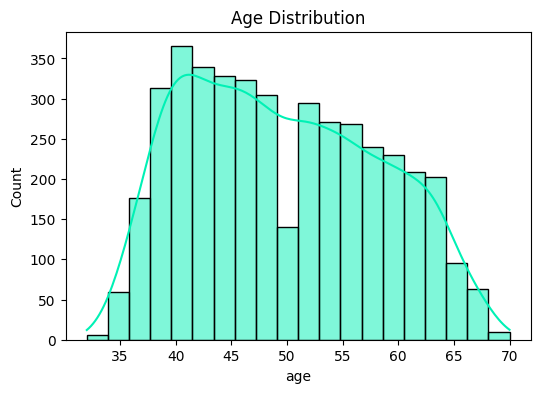

In [11]:
plt.figure(figsize=(6,4))
sns.histplot(df['age'], bins=20, kde=True ,color="#00F1B5")
plt.title("Age Distribution")
plt.show()

Most individuals are middle-aged, which aligns with higher cardiovascular risk in this age group.

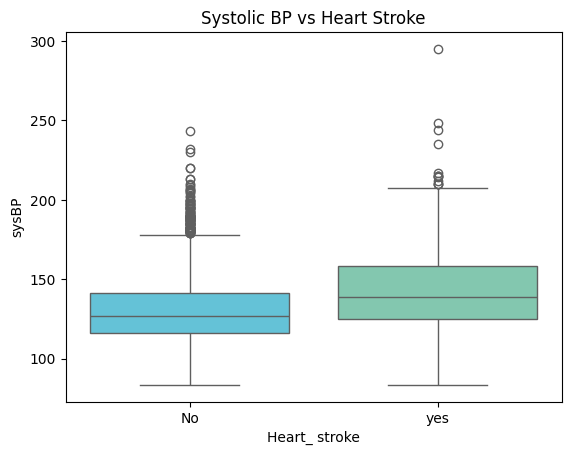

In [12]:
sns.boxplot(x='Heart_ stroke', y='sysBP', data=df, palette=["#51CEEA", "#78D2B2"])
plt.title("Systolic BP vs Heart Stroke")
plt.show()

Patients with heart stroke tend to have higher systolic blood pressure levels.

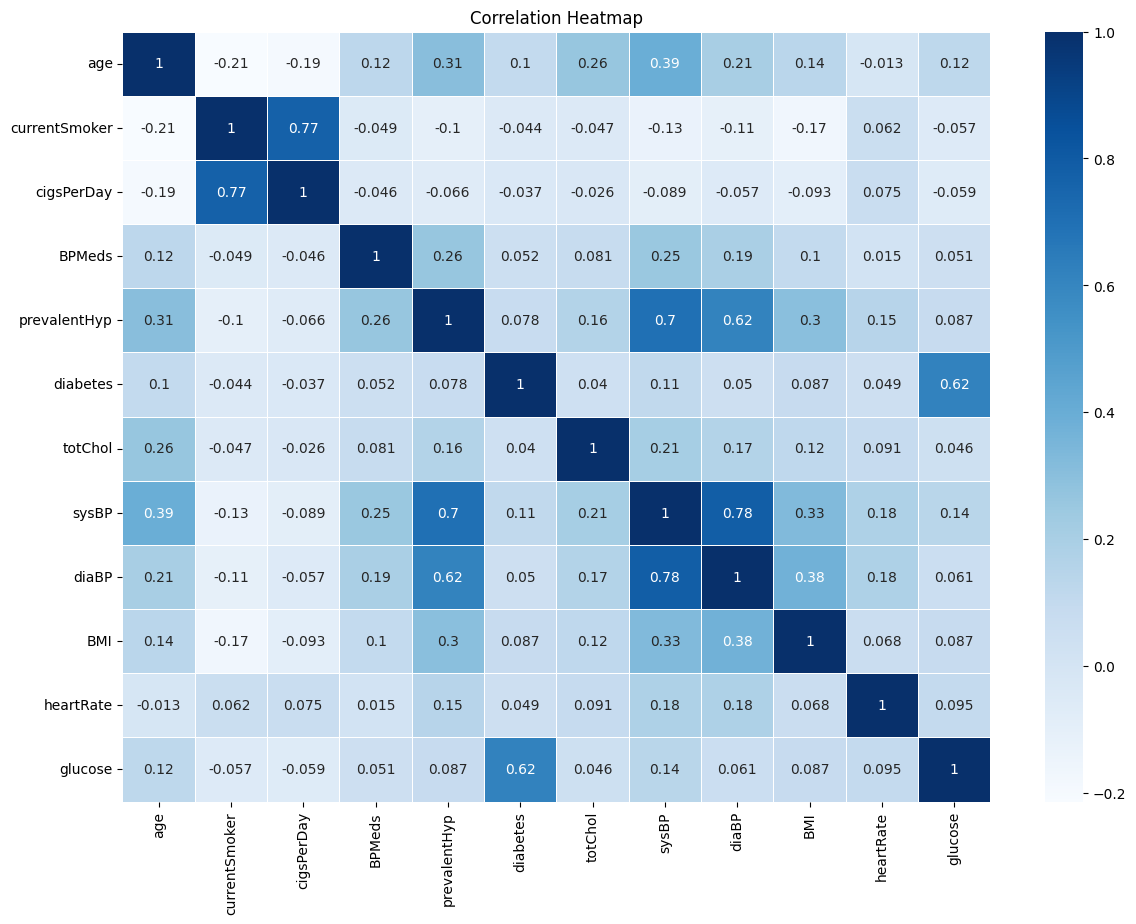

In [13]:
plt.figure(figsize=(14,10))
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap='Blues',
            linewidths=0.5)

plt.title('Correlation Heatmap')
plt.show()


* There is a strong positive correlation between **sysBP and diaBP**, indicating that both blood pressure measures increase together.
* **Age** shows a moderate positive correlation with blood pressure and cholesterol levels.
* **Diabetes** has a strong correlation with **glucose levels**, which is expected clinically.
* Most other features have weak to moderate correlations, indicating limited linear relationships.


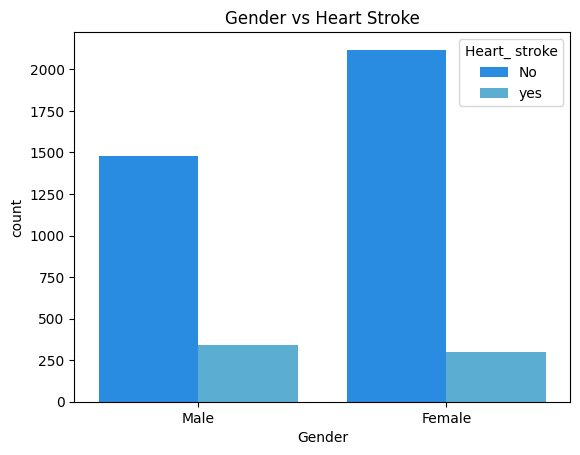

In [14]:
sns.countplot(x='Gender', hue='Heart_ stroke', data=df, palette=["#0C8EFF", "#49B4E5"])
plt.title("Gender vs Heart Stroke")
plt.show()

The plot shows the distribution of heart stroke cases across gender. It helps identify whether males or females are more affected, providing insights into gender-based cardiovascular risk differences

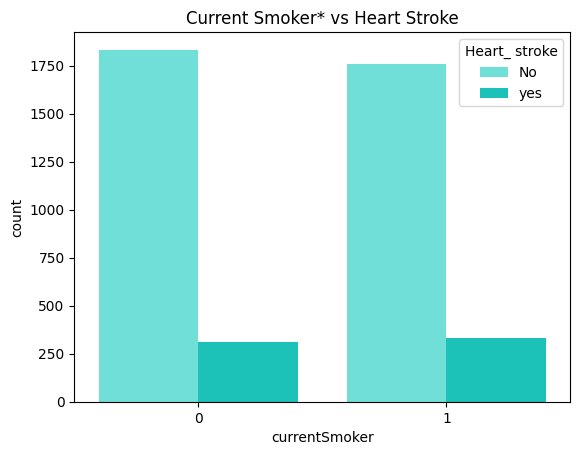

In [15]:
sns.countplot(x='currentSmoker', hue='Heart_ stroke', data=df, palette=["#5DF1E7", "#00DECF"])
plt.title("Current Smoker* vs Heart Stroke")
plt.show()

The plot highlights the relationship between smoking status and heart stroke, showing that smokers tend to have higher incidence of cardiovascular disease.

In [16]:
for col in df.columns:
    print(f"column {col}:")
    print(f"Number of unique values: {len(df[col].value_counts())}")
    print(f"Number of missing values: {df[col].isnull().sum()}")
    print("-" *30)

column Gender:
Number of unique values: 2
Number of missing values: 0
------------------------------
column age:
Number of unique values: 39
Number of missing values: 0
------------------------------
column education:
Number of unique values: 4
Number of missing values: 105
------------------------------
column currentSmoker:
Number of unique values: 2
Number of missing values: 0
------------------------------
column cigsPerDay:
Number of unique values: 33
Number of missing values: 29
------------------------------
column BPMeds:
Number of unique values: 2
Number of missing values: 53
------------------------------
column prevalentStroke:
Number of unique values: 2
Number of missing values: 0
------------------------------
column prevalentHyp:
Number of unique values: 2
Number of missing values: 0
------------------------------
column diabetes:
Number of unique values: 2
Number of missing values: 0
------------------------------
column totChol:
Number of unique values: 248
Number of mi

In [17]:
categorical_cols = df.select_dtypes(include='object').columns
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

print(f"Categorical columns ({len(categorical_cols)}): {list(categorical_cols)}")
print(f"Numerical columns ({len(numerical_cols)}): {list(numerical_cols)}")

Categorical columns (4): ['Gender', 'education', 'prevalentStroke', 'Heart_ stroke']
Numerical columns (12): ['age', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']


In [18]:
for col in categorical_cols:
 print(f"Column {df[col].value_counts()}")
 print("-"*30)

Column Gender
Female    2419
Male      1819
Name: count, dtype: int64
------------------------------
Column education
uneducated       1720
primaryschool    1253
graduate          687
postgraduate      473
Name: count, dtype: int64
------------------------------
Column prevalentStroke
no     4213
yes      25
Name: count, dtype: int64
------------------------------
Column Heart_ stroke
No     3594
yes     644
Name: count, dtype: int64
------------------------------


In [19]:
duplicates = df.duplicated()
print("Number of duplicate rows:", duplicates.sum())

Number of duplicate rows: 0


# preprocessing

In [20]:
df.drop_duplicates(inplace=True)
print("Shape after dropping duplicates:", df.shape)

Shape after dropping duplicates: (4238, 16)


The *Heart_ stroke* column was used to create a binary target variable (1 = yes, 0 = no) for the Genetic Algorithm fitness evaluation.

In [21]:
df['target'] = df['Heart_ stroke'].str.lower().map({'yes': 1, 'no': 0})

The features *Heart_ stroke* and *diabetes* were removed from the dataset during preprocessing. This step was performed to reduce redundancy and avoid potential data leakage in downstream modeling tasks.

In [22]:

cols_to_drop = [
    'Heart_ stroke',
    'diabetes'
]

df = df.drop(columns=cols_to_drop)

print("Dropped columns:", cols_to_drop)
print("New shape:", df.shape)

Dropped columns: ['Heart_ stroke', 'diabetes']
New shape: (4238, 15)


missing filled with median for numerical and mode for categorical

In [23]:

categorical_cols = df.select_dtypes(include='object').columns
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
Gender             0
age                0
education          0
currentSmoker      0
cigsPerDay         0
BPMeds             0
prevalentStroke    0
prevalentHyp       0
totChol            0
sysBP              0
diaBP              0
BMI                0
heartRate          0
glucose            0
target             0
dtype: int64


Outliers were detected using the IQR method and then handled by capping extreme values within the lower and upper bounds.

In [24]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

print("Outliers BEFORE handling:")

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers_count = df[(df[col] < lower) | (df[col] > upper)].shape[0]

    print(f"{col}: {outliers_count}")


for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

print("Outliers handled")

Outliers BEFORE handling:
age: 0
currentSmoker: 0
cigsPerDay: 12
BPMeds: 124
prevalentHyp: 0
totChol: 57
sysBP: 126
diaBP: 81
BMI: 97
heartRate: 76
glucose: 262
target: 644
Outliers handled


Categorical variables were encoded using binary mapping and one-hot encoding.

In [25]:
df_enc = df.copy()

binary_cols = ['prevalentStroke']

binary_map = {'yes': 1, 'no': 0}

for col in binary_cols:
    df_enc[col] = df_enc[col].map(binary_map)

df_enc = pd.get_dummies(df_enc, columns=[
    'Gender',
    'education'
], drop_first=True)

print("Final shape after encoding:", df_enc.shape)

Final shape after encoding: (4238, 17)


Dimensionality reduction was applied to the smoking-related features due to high correlation between them. Principal Component Analysis (PCA) was used to combine them into a single feature, which explained approximately 88% of the variance.


Dimensionality reduction was applied to the blood pressure features (*sysBP* and *diaBP*) due to high correlation between them. PCA was used after standardization to combine them into a single feature, which explains about 89% of the variance.


In [26]:
smoke = df_enc[['currentSmoker', 'cigsPerDay']]

scaler = StandardScaler()
smoke_scaled = scaler.fit_transform(smoke)

pca_smoke = PCA(n_components=1)
df_enc['Smoking_PCA'] = pca_smoke.fit_transform(smoke_scaled)

df_enc = df_enc.drop(columns=['currentSmoker', 'cigsPerDay'])

print("Smoking feature created")
print("Explained variance:", pca_smoke.explained_variance_ratio_)

Smoking feature created
Explained variance: [0.88271825]


In [27]:
bp = df_enc[['sysBP', 'diaBP']]

scaler = StandardScaler()
bp_scaled = scaler.fit_transform(bp)

pca_bp = PCA(n_components=1)
df_enc['BP_PCA'] = pca_bp.fit_transform(bp_scaled)

df_enc = df_enc.drop(columns=['sysBP', 'diaBP'])

print("BP feature created")
print("Explained variance:", pca_bp.explained_variance_ratio_)

BP feature created
Explained variance: [0.89129707]


Scaling data

In [28]:

X = df_enc.copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Final scaling done ")
print("Shape:", X_scaled.shape)

Final scaling done 
Shape: (4238, 15)


In [29]:
print("Remaining features in dataset:")
print(list(df_enc.columns))

Remaining features in dataset:
['age', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'totChol', 'BMI', 'heartRate', 'glucose', 'target', 'Gender_Male', 'education_postgraduate', 'education_primaryschool', 'education_uneducated', 'Smoking_PCA', 'BP_PCA']


## Comparison before / After Preprocessing

- there was missing values in this features ( education ,cigsPerDay ,BPMeds ,totChol ,BMI ,heartRate ,glucose ) after preprocessing it handled using median for numerical and mode for categorical
- there was outliers in this features (cigsPerDay, BPMeds, totChol, sysBP, diaBP, BMI, heartRate, glucose, target) after preprocessing it handled using clipping
- Pca is Applied to reduce the features that highly correlated 
- All the data are scaled
- the categorical coloums are encoded using label encoding
- diabets is removed to decrease redundancy



# k medoids

K-Medoids is a partition-based clustering algorithm that is similar to K-Means but more robust to noise and outliers. Instead of using the mean of data points as the cluster center, K-Medoids selects actual data points (called *medoids*) to represent each cluster.

#### How It Works

1. The algorithm starts by selecting *K* random data points as initial medoids.
2. Each data point is assigned to the nearest medoid based on a manhattan distance
3. For each cluster, the algorithm selects a new medoid that minimizes the total distance between all points in that cluster.
4. Steps 2 and 3 are repeated until the medoids no longer change or the improvement becomes minimal.

#### Why K-Medoids?

* **Robust to Outliers:**
  Unlike K-Means, which uses the mean and can be affected by extreme values, K-Medoids uses actual data points, making it more stable.

* **Works Well with Real-World Data:**
  Medical datasets often contain noise and outliers, so K-Medoids is a suitable choice.

* **Flexible Distance Metrics:**
  It supports different distance measures such as Manhattan distance, which can be more appropriate for certain types of data.

#### Distance Metric Used

In this project, the **Manhattan distance** was used because:

* It is less sensitive to outliers compared to Euclidean distance.
* It works well with scaled numerical features.



### Feature Selection Justification

The features used for K-Medoids clustering were carefully selected based on their strong relevance to cardiovascular health and their ability to differentiate between patient risk profiles.

#### Selected Features:

* **BMI (Body Mass Index):**
  BMI is a key indicator of obesity, which is strongly associated with an increased risk of heart disease and hypertension.

* **Total Cholesterol (totChol):**
  Cholesterol levels play a critical role in cardiovascular health. High cholesterol is directly linked to plaque buildup in arteries and increased heart disease risk.

* **BP_PCA (Blood Pressure PCA):**
  Instead of using systolic and diastolic blood pressure separately, Principal Component Analysis (PCA) was applied to combine them into a single feature.
  This reduces redundancy and captures the overall blood pressure effect more efficiently.

* **Smoking_PCA:**
  Smoking behavior was represented using PCA on *currentSmoker* and *cigsPerDay*.
  This provides a more comprehensive measure of smoking intensity while reducing dimensionality.

* **Prevalent Hypertension (prevalentHyp):**
  This binary feature indicates whether the patient already suffers from hypertension, making it a strong clinical indicator of cardiovascular risk.



* These features represent **major medical risk factors** for heart disease:

  * Lifestyle factors : (Smoking, BMI)
  * Clinical measurements : (Blood Pressure, Cholesterol)
  * Existing conditions : (Hypertension)

* They provide a **balanced combination** of behavioral and physiological indicators.

* Redundant features were reduced using PCA, improving clustering performance and avoiding multicollinearity.


#### Conclusion

The selected features allow the clustering algorithm to group individuals into meaningful segments based on their overall cardiovascular risk, enabling clear identification of low-risk, moderate-risk, and high-risk groups.


In [30]:
features = [
    'BMI',
    'totChol',
    'BP_PCA',
    'Smoking_PCA',
    'prevalentHyp',
]

X = df_enc[features]

In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### Elbow Method for Optimal Number of Clusters

To determine the optimal number of clusters (( K )) for the K-Medoids algorithm, the Elbow Method was applied.

#### Concept

The Elbow Method evaluates how the clustering performance changes as the number of clusters increases. It uses the **inertia** (total distance between data points and their assigned medoids) as a measure of cluster compactness.

* Lower inertia : better clustering (points are closer to their medoids)
* However, increasing ( K ) always reduces inertia, so the goal is to find a balance

#### Methodology

The K-Medoids algorithm was applied for different values of ( K ) (from 2 to 10), and the corresponding inertia values were calculated and plotted.

#### Result

The resulting curve shows a sharp decrease in inertia when increasing ( K ) from 2 to 3, followed by a more gradual decline for higher values of ( K ).

This creates an "elbow" shape in the graph.

#### Interpretation

The elbow point occurs at **( K = 3 )**, where adding more clusters does not significantly improve the clustering performance.

* Before ( K = 3 ): large improvement in compactness
* After ( K = 3 ): diminishing returns

#### Conclusion

Based on the Elbow Method, the optimal number of clusters is **3**, as it provides a good balance between model simplicity and clustering quality without overfitting.


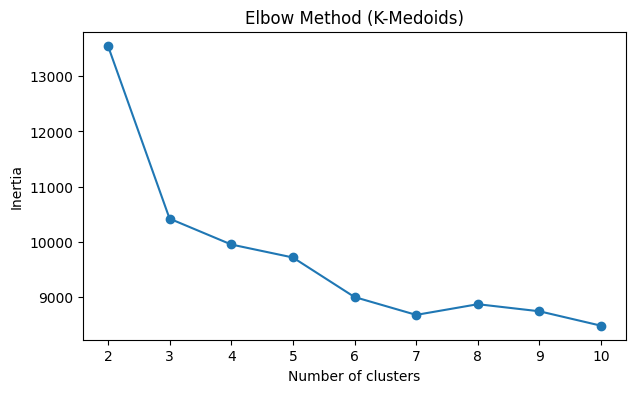

In [32]:

inertia = []

K = range(2, 11)

for k in K:
    kmedoids = KMedoids(n_clusters=k, metric='manhattan', random_state=42)
    kmedoids.fit(X_scaled)
    inertia.append(kmedoids.inertia_)

plt.figure(figsize=(7,4))
plt.plot(K, inertia, marker='o')
plt.title("Elbow Method (K-Medoids)")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.show()

### Silhouette Score Evaluation

To further evaluate the quality of clustering, the **Silhouette Score** was used as a validation metric.

#### Concept

The Silhouette Score measures how well each data point fits within its assigned cluster compared to other clusters. It considers two main factors:

* **Cohesion:** How close a point is to other points in the same cluster
* **Separation:** How far a point is from points in other clusters

The score ranges from **-1 to 1**:

* **Close to 1:** Well-separated and clearly defined clusters
* **Around 0:** Overlapping clusters
* **Negative values:** Incorrect clustering

#### Methodology

The Silhouette Score was calculated for different values of ( K ) (from 2 to 10) using the K-Medoids algorithm.

#### Result

The highest Silhouette Score was observed at **( K = 3 )** with a value of approximately **0.27**.

#### Interpretation

* A score of **0.27** indicates **moderate cluster separation**
* The clusters are reasonably distinct, but there is some overlap between them
* This is expected in real-world medical data, where boundaries between risk groups are not always sharply defined

#### Conclusion

The Silhouette analysis confirms that **( K = 3 )** is the optimal number of clusters, as it provides the best balance between cohesion and separation among all tested values.


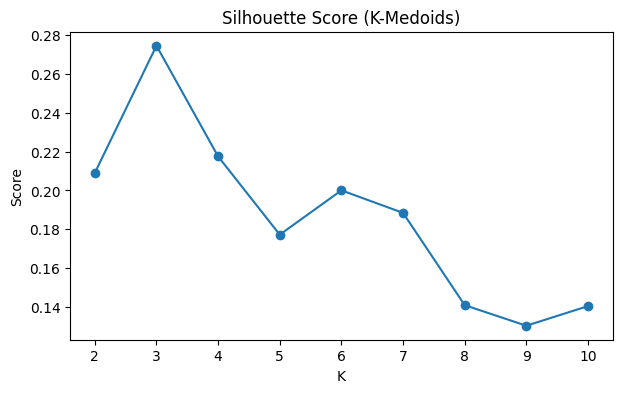

In [33]:
sil_scores = []

for k in K:
    kmedoids = KMedoids(n_clusters=k, metric='manhattan', random_state=42)
    labels = kmedoids.fit_predict(X_scaled)

    if len(np.unique(labels)) > 1:
        score = silhouette_score(X_scaled, labels)
    else:
        score = -1

    sil_scores.append(score)

plt.figure(figsize=(7,4))
plt.plot(K, sil_scores, marker='o')
plt.title("Silhouette Score (K-Medoids)")
plt.xlabel("K")
plt.ylabel("Score")
plt.show()

In [34]:
best_k = K[sil_scores.index(max(sil_scores))]
print("Best K =", best_k)

Best K = 3


In [35]:
kmedoids = KMedoids(n_clusters=best_k, metric='manhattan', random_state=42)
labels = kmedoids.fit_predict(X_scaled)

df_enc['Cluster'] = labels

### Cluster Visualization (PCA Projection)

The 2D PCA projection reveals three visually distinct groups with minimal
overlap, confirming that the clusters capture genuine structure in the data
rather than arbitrary partitions.


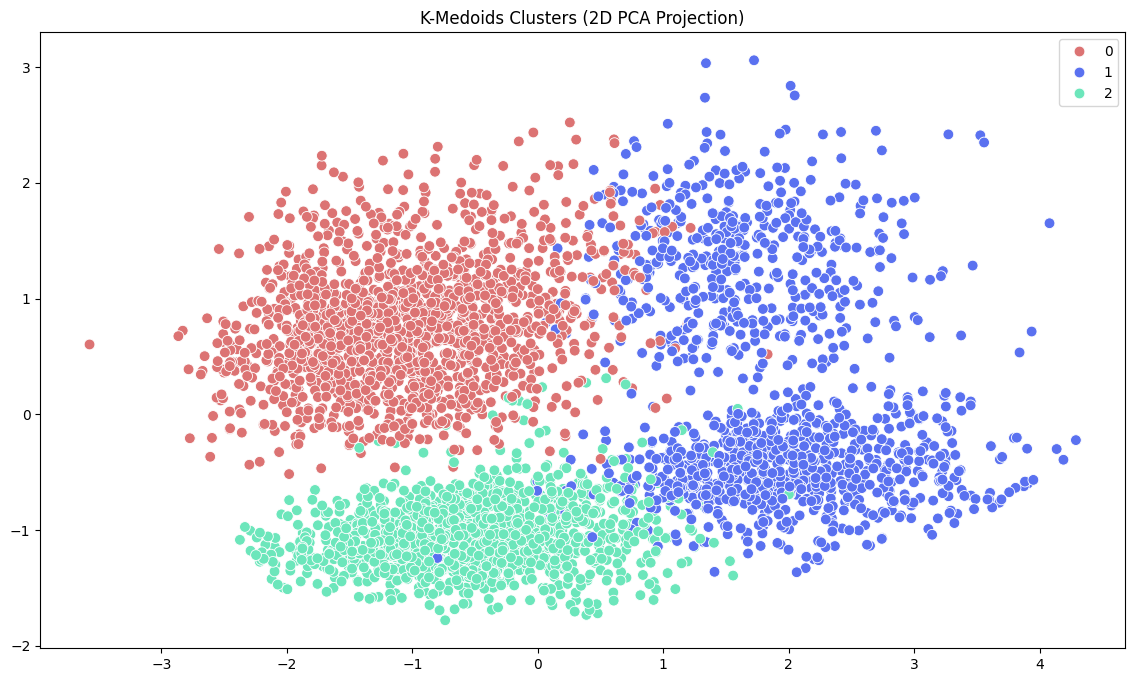

In [36]:
labels = kmedoids.labels_

pca_vis = PCA(n_components=2)
X_2d = pca_vis.fit_transform(X_scaled)

plt.figure(figsize=(14,8))
sns.scatterplot(
    x=X_2d[:,0],
    y=X_2d[:,1],
    hue=labels,
    palette=["#DC7373", "#5A71F0", "#6CE6BB"],
    s=60

)

plt.title("K-Medoids Clusters (2D PCA Projection)")
plt.show()

In [37]:
df_enc.groupby('Cluster').mean()

,age,BPMeds,prevalentStroke,prevalentHyp,totChol,BMI,heartRate,glucose,target,Gender_Male,education_postgraduate,education_primaryschool,education_uneducated,Smoking_PCA,BP_PCA
Cluster,,,,,,,,,,,,,,,
0,46.567738,0.0,0.001260,0.039698,230.098299,24.348576,75.582546,78.264335,0.0,0.511027,0.114682,0.339635,0.384373,1.280395,-0.70005
1,53.657622,0.0,0.014366,1.000000,247.107741,27.566615,78.239425,80.992019,0.0,0.418196,0.097366,0.268955,0.498803,-0.269929,1.48263
2,49.359800,0.0,0.003577,0.000000,233.324750,25.607972,73.710658,79.420243,0.0,0.346209,0.120887,0.269671,0.422031,-1.211563,-0.53416


## Cluster 0 - moderate-risk group
- Average Age: ~46 (relatively younger)
- Blood Pressure: Low (negative BP_PCA)
- Cholesterol: Moderate (~230)
- BMI: Normal (~24)
- Smoking: High (positive Smoking_PCA)
- Hypertension: Very low prevalence

>  This cluster represents generally healthy individuals hey seem fine now but the smoking habit is a flag for future risk.


## Cluster 1 - high-risk group
- Average Age: ~54 (older group)
- Hypertension: 100% prevalence
- Cholesterol: High (~247)
- BMI: Elevated (~27.5)
- Blood Pressure: Very high (high BP_PCA)
- Heart Rate: Slightly higher
- Smoking: Moderate

>  This is the highest-risk cluster.These are the patients that need the most attention clinically.


## Cluster 2 -  Low Risk Group
- Average Age: ~49 (middle-aged)
- Blood Pressure: Low
- Cholesterol: Moderate
- BMI: Healthy (~25)
- Smoking: Very low (strong negative Smoking_PCA)
- Hypertension: Almost nonexistent

>   This cluster represents the healthiest group, with stable medical indicators and minimal behavioral risks such as smoking.


# Hierarchical Clustering

As required , i will generate three dendrogram to visualize the best n clusters and best method

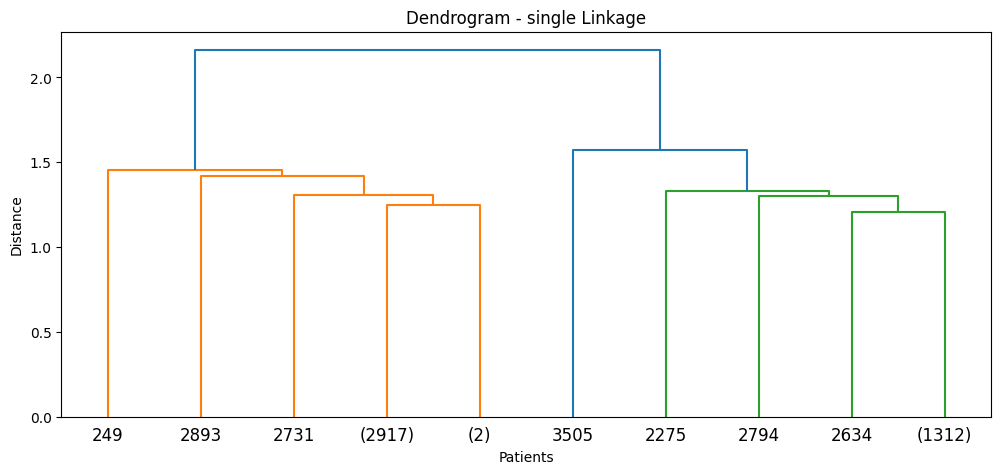

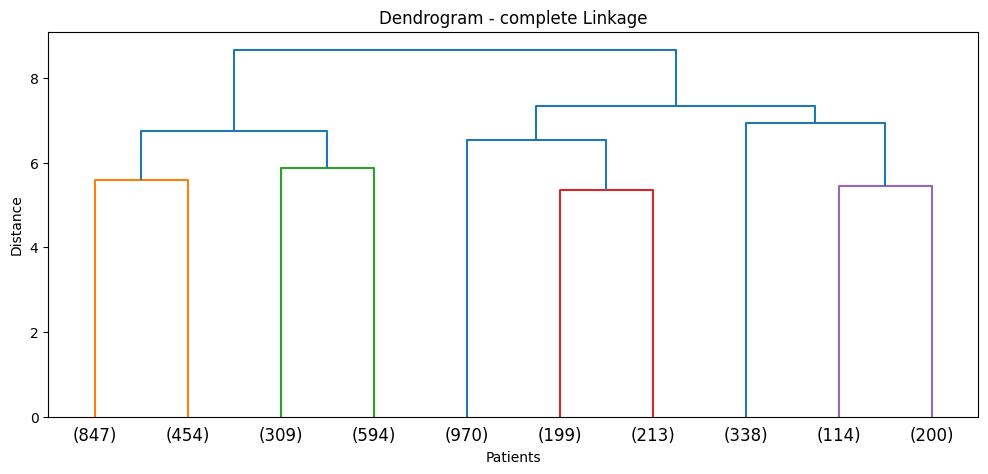

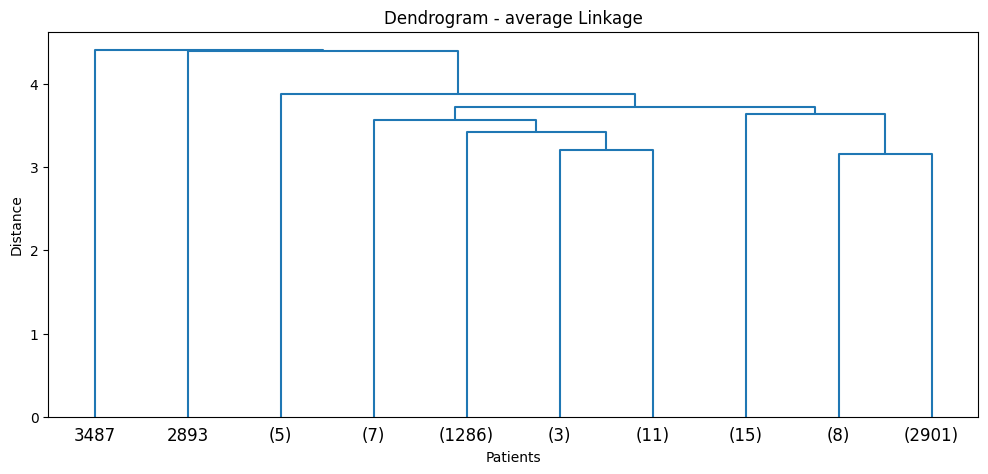

In [38]:

methods = ['single', 'complete', 'average']

for method in methods:
    plt.figure(figsize=(12,5))
    sch.dendrogram(sch.linkage(X_scaled, method=method),truncate_mode='lastp',p=10)
    plt.title(f'Dendrogram - {method} Linkage')
    plt.xlabel('Patients')
    plt.ylabel('Distance')
    plt.show()


in the previous diagrams,we can see that the Complete Linkage method with two clusters appears to be the most effective. To further validate these results, I will evaluate the performance using metrics such as the
**Silhouette Score**

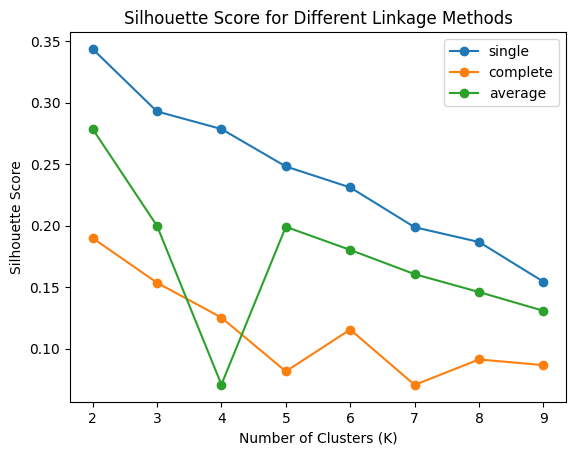

In [39]:

k_values = range(2, 10)
results = {}

for method in methods:
    sil_scores = []

    for k in k_values:
        model = AgglomerativeClustering(n_clusters=k, linkage=method)
        labels = model.fit_predict(X_scaled)
        score = silhouette_score(X_scaled, labels)
        sil_scores.append(score)

    results[method] = sil_scores

    plt.plot(k_values, sil_scores, marker='o', label=method)

plt.title("Silhouette Score for Different Linkage Methods")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.legend()
plt.show()

Based on the **Silhouette Score**, two clusters are indeed appropriate. However, the diagrams suggest that Single Linkage might be a better starting point. To further confirm the optimal number of clusters, I will now apply the **Elbow Method**

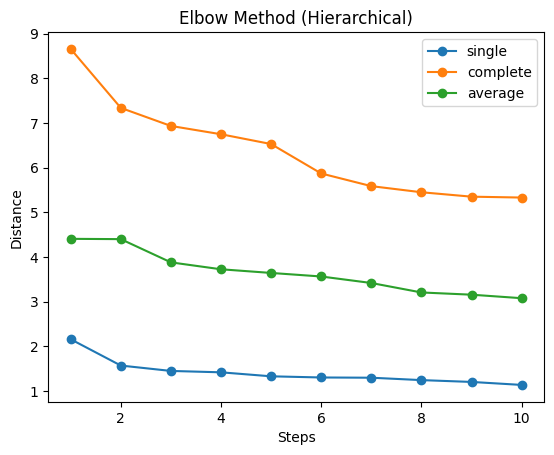

In [40]:

for method in methods:
    Z = sch.linkage(X_scaled, method=method)

    last = Z[-10:, 2]
    last_rev = last[::-1]

    plt.plot(range(1, 11), last_rev, marker='o', label=method)

plt.title("Elbow Method (Hierarchical)")
plt.xlabel("Steps")
plt.ylabel("Distance")
plt.legend()
plt.show()

The Elbow Method confirms that the optimal number of clusters is two. Combined with our previous analysis, the Complete Linkage method stands out as the most effective approach. Therefore, we will proceed with n=2 and Complete Linkage for the **Agglomerative Clustering model**

In [41]:

best_method = 'complete'
best_k = 2

model = AgglomerativeClustering(
    n_clusters=best_k,
    linkage=best_method
)

clusters = model.fit_predict(X_scaled)

add the clustering results to the data

In [42]:
df_enc['Hierarchical_Cluster'] = clusters
df_enc.head()

,age,BPMeds,prevalentStroke,prevalentHyp,totChol,BMI,heartRate,glucose,target,Gender_Male,education_postgraduate,education_primaryschool,education_uneducated,Smoking_PCA,BP_PCA,Cluster,Hierarchical_Cluster
0,39,0.0,0,0,195.0,26.97,80.0,77.0,0,True,True,False,False,-1.233710,-1.678166,2,0
1,46,0.0,0,0,250.0,28.73,95.0,76.0,0,False,False,True,False,-1.233710,-0.481411,2,0
2,48,0.0,0,0,245.0,25.34,75.0,70.0,0,True,False,False,True,1.381160,-0.320869,0,1
3,61,0.0,0,1,225.0,28.58,65.0,103.0,0,False,False,False,False,1.981439,1.381128,1,0
4,46,0.0,0,0,285.0,23.10,85.0,85.0,0,False,False,False,False,1.561244,0.013118,0,1


To understand the characteristics of each cluster, I calculated the mean values for all features grouped by the cluster labels

In [43]:




cluster_summary = df_enc.groupby('Hierarchical_Cluster').mean()
print(cluster_summary)



                            age  BPMeds  prevalentStroke  prevalentHyp  \
Hierarchical_Cluster                                                     
0                     51.617994     0.0         0.009341      0.577679   
1                     47.708711     0.0         0.002722      0.063975   

                         totChol        BMI  heartRate    glucose  target  \
Hierarchical_Cluster                                                        
0                     241.219272  28.059371  76.670108  80.303589     0.0   
1                     231.551724  23.552334  74.901996  78.666289     0.0   

                      Gender_Male  education_postgraduate  \
Hierarchical_Cluster                                        
0                        0.461652                0.099312   
1                        0.399274                0.122958   

                      education_primaryschool  education_uneducated  \
Hierarchical_Cluster                                                  
0      

Since the dataset contains multiple features, I applied Principal Component Analysis (PCA) to reduce the dimensionality to two main components for visualization purposes

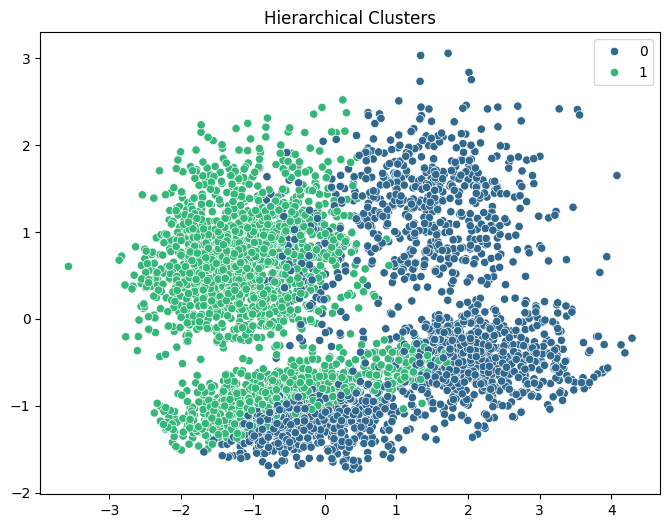

In [44]:
pca_vis = PCA(n_components=2)
X_2d = pca_vis.fit_transform(X_scaled)

plt.figure(figsize=(8,6))

sns.scatterplot(
    x=X_2d[:,0],
    y=X_2d[:,1],
    hue=clusters,
    palette='viridis'
)

plt.title("Hierarchical Clusters")
plt.show()



---



# Fuzzy



> Fuzzy Logic System Overview



This fuzzy logic system is designed to model a decision-making process based on key health-related and behavioral features extracted from the dataset. The system incorporates both physiological measurements and clustering results obtained from K-Medoid.

Specifically, the system uses Age and Heart Rate as numerical indicators, along with the Cluster Label to capture hidden patterns identified through clustering.

The main objective is to transform these inputs into an interpretable output representing the individual's Risk Level, enabling a human-like reasoning approach for decision-making.



> System Variables

The fuzzy system is built using the following variables:

1- Input Variables:

Age: Represents the age of the individual and is a key factor influencing health-related risks.
Heart Rate: Represents the number of heartbeats per minute, reflecting the individual's physiological condition.
Cluster Label: Represents the group assigned through clustering, capturing underlying behavioral or medical patterns in the dataset.

2- Output Variable:

Risk Level: Represents the final decision of the system, categorized into linguistic terms such as Safe, Warning, and Danger.
These variables were selected due to their combined ability to reflect both observable health indicators and hidden patterns within the data.

In [45]:
#Define antecedents (inputs)
cluster = ctrl.Antecedent(np.arange(0, 3, 1), 'cluster')
age = ctrl.Antecedent(np.arange(20, 81, 1), 'age')
heart_rate = ctrl.Antecedent(np.arange(40, 221, 1), 'heart_rate')

In [46]:
# Define consequents (outputs)
risk = ctrl.Consequent(np.arange(0, 101, 1), 'risk')

    Membership Functions Design

Each variable is represented using fuzzy membership functions to allow smooth transitions between categories.

Age was divided into three linguistic categories: Young, Middle-aged, and Senior. The ranges were selected based on the dataset distribution.
Heart Rate was categorized into Low, Normal, and High, reflecting physiological conditions.
Cluster Label was treated as a fuzzy variable representing different underlying groups (e.g., Low-Risk Zone, Medium-Risk Zone, High-Risk Zone).
Risk Level (output) was defined as Safe, Warning, and Danger.
Triangular or trapezoidal membership functions were used due to their simplicity and interpretability. The boundaries were chosen based on both domain knowledge and data distribution.

In [47]:
# Define fuzzy membership functions
# Set the membership functions for the input variables
cluster['low_risk_zone'] = fuzz.trimf(cluster.universe, [0, 0, 1])
cluster['med_risk_zone'] = fuzz.trimf(cluster.universe, [0, 1, 2])
cluster['high_risk_zone'] = fuzz.trimf(cluster.universe, [1, 2, 2])

age['young'] = fuzz.trapmf(age.universe, [20, 20, 30, 45])
age['middle_aged'] = fuzz.trimf(age.universe, [35, 50, 65])
age['senior'] = fuzz.trapmf(age.universe, [55, 70, 80, 80])

heart_rate['low'] = fuzz.trapmf(heart_rate.universe, [40, 40, 60, 100])
heart_rate['normal'] = fuzz.trimf(heart_rate.universe, [90, 140, 180])
heart_rate['high'] = fuzz.trapmf(heart_rate.universe, [170, 200, 220, 220])

# Set the membership functions for the output variable
risk['safe'] = fuzz.trapmf(risk.universe, [0, 0, 20, 40])
risk['warning'] = fuzz.trimf(risk.universe, [30, 50, 70])
risk['danger'] = fuzz.trapmf(risk.universe, [60, 80, 100, 100])

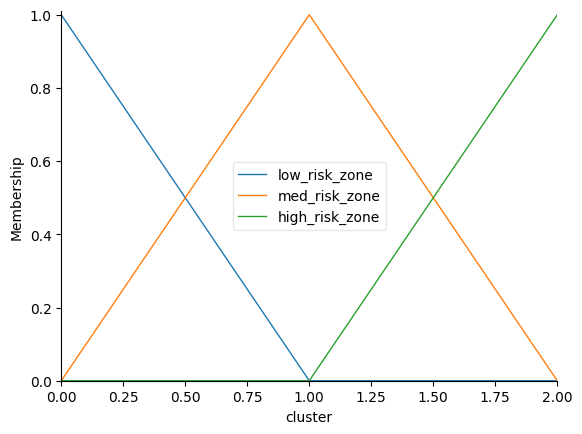

In [48]:
cluster.view()

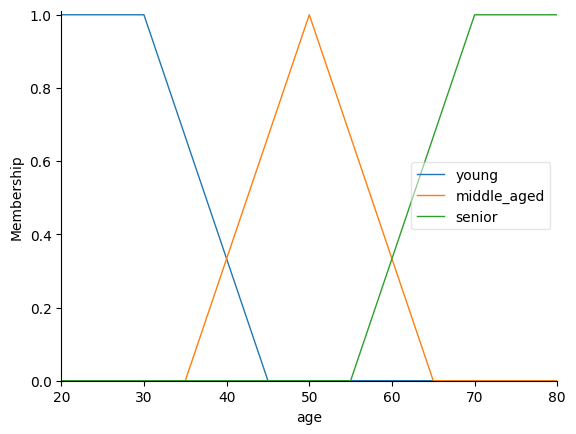

In [49]:
age.view()

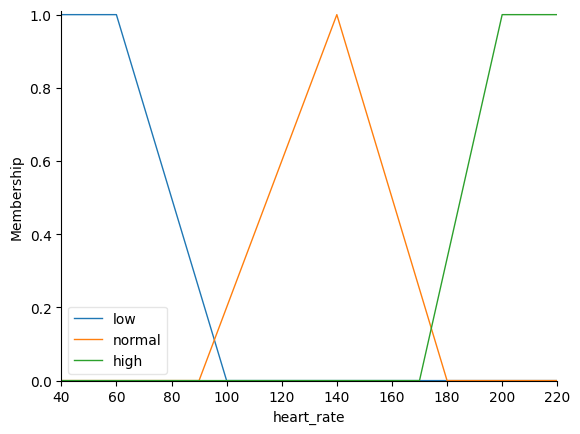

In [50]:



heart_rate.view()

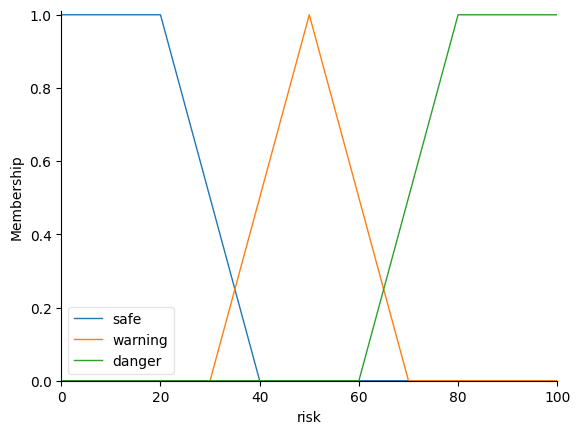

In [51]:
risk.view()

**Rule Base Explanation**

This rule base is designed to be "Bulletproof," meaning it leaves no gaps in the data. By using logical operators like OR (|) and NOT (~), we ensured that every patient—no matter their age or heart rate—is covered by at least one rule.

High-Risk Group (Danger Zone)
Why: To catch the most critical cases using both clustering and medical signals.

Logic: A patient is in Danger if they belong to a "High-Risk Cluster" OR if they are a "Senior with a High Heart Rate." We also flag seniors with "Low Heart Rate" as danger because it may indicate heart failure.

Moderate-Risk Group (Warning Zone)
Why: To monitor patients who are not in immediate danger but have concerning factors.

Logic: Middle-aged patients with any abnormal heart rate (High or Low) get a Warning. We also include seniors who have a "Normal Heart Rate" but are NOT in a safe cluster, ensuring we don't ignore them just because their pulse is steady.

Low-Risk Group (Safe Zone)
Why: To identify healthy individuals accurately.

Logic: The system only gives a Safe status to young or middle-aged patients who have a "Normal Heart Rate" and are NOT in a high-risk cluster. This triple-check ensures that "Safe" truly means low risk.


---


**Why these rules are "Meaningful"?**

100% Data Coverage: It eliminates "Dead Zones." Every row in the dataset will now produce a valid Risk percentage.

Smart Integration: It treats the Cluster as a powerful evidence. If the Clustering model (Unsupervised) and the Fuzzy logic (Inference) both agree, the confidence in the result is much higher.

Balanced Logic: It respects medical facts (like age being a risk) while staying flexible enough to handle different heart rate scenarios.

In [52]:
# Define fuzzy rules
rules = []

# Rules for High Risk (3 Rules)
rules.append(ctrl.Rule(cluster['high_risk_zone'] | (age['senior'] & heart_rate['high']), risk['danger']))
rules.append(ctrl.Rule(age['senior'] & heart_rate['low'], risk['danger']))
rules.append(ctrl.Rule(cluster['high_risk_zone'] & heart_rate['normal'], risk['danger']))

# Rules for Medium Risk (3 Rules)
rules.append(ctrl.Rule(age['middle_aged'] & (heart_rate['high'] | heart_rate['low']), risk['warning']))
rules.append(ctrl.Rule(age['senior'] & heart_rate['normal'] & (cluster['low_risk_zone'] | cluster['med_risk_zone']), risk['warning']))
rules.append(ctrl.Rule(age['young'] & heart_rate['high'], risk['warning']))

# Rules for Safe (3 Rules)
rules.append(ctrl.Rule(age['young'] & heart_rate['normal'], risk['safe']))
rules.append(ctrl.Rule(age['young'] & heart_rate['low'], risk['safe']))
rules.append(ctrl.Rule(age['middle_aged'] & heart_rate['normal'] & (cluster['low_risk_zone'] | cluster['med_risk_zone']), risk['safe']))

> Inference Mechanism and Defuzzification



After evaluating all rules, the resulting fuzzy outputs are aggregated into a single fuzzy set. To convert this into a crisp value, the centroid (center of gravity) defuzzification method was applied.

The centroid method was selected because it provides a balanced and smooth output, making it suitable for real-world decision-making scenarios.

In [53]:
#Create fuzzy control system
heart_risk_sys = ctrl.ControlSystem(rules)

In [54]:
# Create fuzzy simulator
heart_risk_sim = ctrl.ControlSystemSimulation(heart_risk_sys)

In [55]:
# FIS function for implementation
def fuzzy_inference_system(cluster, age, heart_rate):
  # Set input values
  heart_risk_sim.input['cluster'] = cluster
  heart_risk_sim.input['age'] = age
  heart_risk_sim.input['heart_rate'] = heart_rate

  # Run simulator
  # Evaluate the control system
  heart_risk_sim.compute()

  # Get output value
  try:
        fuzzy_output = heart_risk_sim.output['risk']
  except KeyError:
        fuzzy_output = np.nan # Assign NaN if defuzzification fails(Safety step)
  return fuzzy_output



> System Evaluation


The fuzzy logic system was evaluated using real samples from the dataset.

The results showed that individuals with higher Age and elevated Heart Rate, especially those belonging to high-risk clusters, tend to receive higher Risk Level outputs. Conversely, younger individuals with normal heart rate and belonging to low-risk clusters tend to have lower risk values.

These observations align with expected domain behavior, indicating that the system produces logical and meaningful results.

In [56]:
samples = df_enc.sample(5)

results_list = []

for index, row in samples.iterrows():
    fuzzy_output = fuzzy_inference_system(row['Cluster'], row['age'], row['heartRate'])

    results_list.append({
        'Age': row['age'],
        'HeartRate': row['heartRate'],
        'Cluster': row['Cluster'],
        'Fuzzy Risk %': round(fuzzy_output, 2)
    })


results_df = pd.DataFrame(results_list)

results_df

,Age,HeartRate,Cluster,Fuzzy Risk %
0,41,80.0,2,64.36
1,47,73.0,2,71.75
2,59,53.0,2,74.42
3,65,65.0,2,84.44
4,50,56.0,2,70.81




> Technical Analysis of the High-Risk Case



To verify the system's performance, we analyzed the case with the highest calculated Fuzzy Risk. In this scenario, the patient's data triggered the 'Danger' rules due to the combination of high age, abnormal heart rate, and being categorized in the high-risk cluster.

As shown in the visualization, the 'Danger' Membership Function (Green) is highly activated, which shifted the Centroid (Black Line) significantly to the right (above 80%). This demonstrates that the fuzzy rule base successfully prioritizes critical clinical factors to identify patients who require immediate medical attention.

Case Study (Highest Risk): Age 65.0, HR 65.0, Cluster 2.0
Calculated Fuzzy Risk: 84.44%


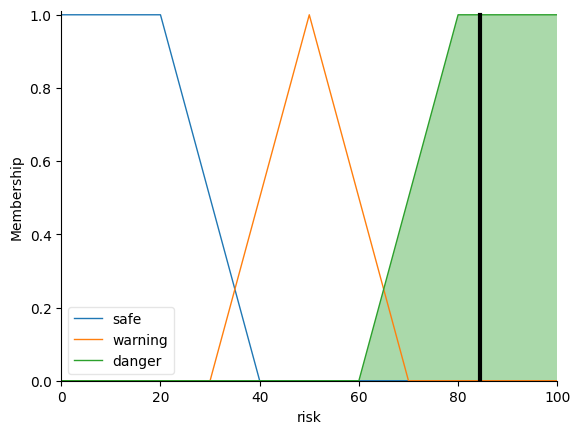

In [57]:
# Select one specific patient from the sample for detailed analysis
# Let's pick the highest risk row
highest_risk_row = results_df.loc[results_df['Fuzzy Risk %'].idxmax()]

# Run the simulation for this specific case
heart_risk_sim.input['cluster'] = highest_risk_row['Cluster']
heart_risk_sim.input['age'] = highest_risk_row['Age']
heart_risk_sim.input['heart_rate'] = highest_risk_row['HeartRate']
heart_risk_sim.compute()

# Display the Centroid Visualization
print(f"Case Study (Highest Risk): Age {highest_risk_row['Age']}, HR {highest_risk_row['HeartRate']}, Cluster {highest_risk_row['Cluster']}")
print(f"Calculated Fuzzy Risk: {heart_risk_sim.output['risk']:.2f}%")

risk.view(sim=heart_risk_sim)



> Interpretation of Results



The output of the fuzzy system represents a meaningful risk assessment that can be used in practical applications such as health monitoring and early risk detection.

By combining Age, Heart Rate, and clustering information, the system captures both direct physiological indicators and hidden patterns in the data.

This enhances the interpretability of the model and provides a human-like reasoning framework for analyzing complex datasets and supporting decision-making processes.

# Genetic Algorithm (as tunning paramater)

- Chromosome: Represents fuzzy parameters (age, heart rate, risk thresholds)
- Gene: Each value inside the chromosome (g1, g2, g3, g4)
- Crossover: Swapping parts between two parents
- Mutation: Randomly modifying one gene
- Population: Set of candidate solutions

Chromosomes were randomly generated to represent fuzzy logic parameters for the Genetic Algorithm.

In [58]:
import random

def create_chromosome():
    g1 = random.uniform(35, 50) # End of youth
    g2 = random.uniform(45, 60)  # The pinnacle of middle age
    g3 = random.uniform(120, 160) # Normal heartbeat
    g4 = random.uniform(40, 60)  # Warning point

    return [g1, g2, g3, g4]

The fitness function evaluates each chromosome by dynamically adjusting fuzzy membership functions and measuring prediction error using Mean Absolute Error (MAE). The fitness score is defined as the inverse of the error to ensure that better solutions receive higher fitness values.

In [59]:
def calculate_fitness(chromosome, df, heart_risk_sim):
    try:
        g_age_end, g_age_peak, g_hr_peak, g_risk_peak = chromosome

        g_age_end = np.clip(g_age_end, 35, 60)
        g_age_peak = np.clip(g_age_peak, 45, 70)
        g_hr_peak = np.clip(g_hr_peak, 120, 180)
        g_risk_peak = np.clip(g_risk_peak, 30, 70)

        age['young'].mf = fuzz.trapmf(age.universe, [20, 20, 30, g_age_end])
        a, b, c = sorted([g_age_end - 5, g_age_peak, 65])
        age['middle_aged'].mf = fuzz.trimf(age.universe, [a, b, c])
        a, b, c = sorted([90, g_hr_peak, 180])
        heart_rate['normal'].mf = fuzz.trimf(heart_rate.universe, [a, b, c])

        a, b, c = sorted([30, g_risk_peak, 70])
        risk['warning'].mf = fuzz.trimf(risk.universe, [a, b, c])


        errors = []

        sample_data = df.sample(20)

        for _, row in sample_data.iterrows():

            heart_risk_sim.input['age'] = row['age']
            heart_risk_sim.input['heart_rate'] = row['heartRate']
            heart_risk_sim.input['cluster'] = row['Cluster']

            heart_risk_sim.compute()

            predicted = heart_risk_sim.output['risk'] / 100
            actual = row['target']

            errors.append(abs(predicted - actual))


        mae = np.mean(errors)
        return 1 / (mae + 1e-6)

    except Exception as e:
        print("ERROR:", e)
        return 0.0001

Parent selection was performed by choosing the highest fitness chromosomes.

In [60]:
def selection(population, fitness_scores, num_parents):

    fitness_array = np.array(fitness_scores)
    sorted_indices = np.argsort(fitness_array)[::-1]

    parents = []
    for i in range(num_parents):
        best_index = sorted_indices[i]
        parents.append(population[best_index])

    return parents

The best individuals based on fitness were selected as parents.

In [61]:
def selection(population, fitness_scores, num_parents=2):

    fitness_array = np.array(fitness_scores)
    sorted_indices = np.argsort(fitness_array)[::-1]

    parents = []
    for i in range(num_parents):
        best_index = sorted_indices[i]
        parents.append(population[best_index])

    return parents

Crossover combines two parents by swapping parts of their chromosomes to generate new children.

In [62]:
def crossover(parent1, parent2):

    crossover_point = random.randint(1, 3)

    child1 = parent1[:crossover_point] + parent2[crossover_point:]
    child2 = parent2[:crossover_point] + parent1[crossover_point:]

    return child1, child2

Mutation was applied to introduce randomness into the Genetic Algorithm by randomly modifying one gene in a chromosome based on a predefined mutation rate.

In [63]:
def mutation(chromosome, mutation_rate=0.3):

    if random.random() < mutation_rate:

        gene_index = random.randint(0, 3)

        change = random.uniform(-10, 10)
        chromosome[gene_index] += change

    return chromosome

The Genetic Algorithm was implemented by initializing a population of random chromosomes and iteratively improving them over multiple generations. In each generation, fitness is evaluated, the best solutions are selected, and new offspring are generated using selection, crossover, and mutation. The best chromosome is preserved to ensure solution quality improves over time.

In [64]:
def GA(population_size, generations, df, heart_risk_sim):

    population = [create_chromosome() for _ in range(population_size)]

    best_global = None
    best_global_fitness = -np.inf

    for generation in range(generations):

        fitness_scores = [calculate_fitness(chrom, df, heart_risk_sim) for chrom in population]

        pop_with_fitness = sorted(zip(population, fitness_scores), key=lambda x: x[1], reverse=True)
        population = [x[0] for x in pop_with_fitness]

        current_best_fitness = pop_with_fitness[0][1]
        best_chromosome = population[0]

        if current_best_fitness > best_global_fitness:
            best_global_fitness = current_best_fitness
            best_global = best_chromosome

        print(f"Generation {generation + 1}:")
        print(f"Best Chromosome: {best_chromosome}")
        print(f"Fitness (Score): {current_best_fitness:.6f}")
        print("-" * 20)

        new_population = [best_chromosome]

        for _ in range(2):
            new_population.append(create_chromosome())

        while len(new_population) < population_size:

            parents = selection(population, fitness_scores, num_parents=2)
            parent1, parent2 = parents[0], parents[1]

            child1, child2 = crossover(parent1, parent2)

            child1 = mutation(child1)
            child2 = mutation(child2)

            new_population.append(child1)
            if len(new_population) < population_size:
                new_population.append(child2)

        population = new_population

    return best_global, best_global_fitness

The GA was run to find the best chromosome and its fitness score as the final optimized result.


In [65]:
best_solution, best_fitness = GA(
    population_size=30,
    generations=20,
    df=df_enc,
    heart_risk_sim=heart_risk_sim
)

print("Best Solution:", best_solution)
print(f"Best Fitness: {best_fitness:.6f}")

Generation 1:
Best Chromosome: [48.0405463021026, 59.86578719956969, 120.33746567597967, 46.20558686448521]
Fitness (Score): 2.121709
--------------------
Generation 2:
Best Chromosome: [48.0405463021026, 59.86578719956969, 120.33746567597967, 46.20558686448521]
Fitness (Score): 2.197852
--------------------
Generation 3:
Best Chromosome: [48.0405463021026, 59.301450554011254, 129.25067475509928, 40.32033890387828]
Fitness (Score): 2.241258
--------------------
Generation 4:
Best Chromosome: [48.0405463021026, 59.20710418184605, 120.33746567597967, 46.20558686448521]
Fitness (Score): 2.217227
--------------------
Generation 5:
Best Chromosome: [48.0405463021026, 59.20710418184605, 120.33746567597967, 46.20558686448521]
Fitness (Score): 2.201919
--------------------
Generation 6:
Best Chromosome: [48.0405463021026, 59.20710418184605, 120.33746567597967, 50.23081466279257]
Fitness (Score): 2.320746
--------------------
Generation 7:
Best Chromosome: [41.56355182767253, 54.68714905563709,

## Genetic Algorithm Results

The Genetic Algorithm was executed for 20 generations to optimize the parameters of the fuzzy membership functions. Below are the results showing the best chromosome and its corresponding fitness value for each generation.

The fitness values represent the inverse of the Mean Absolute Error (MAE), where higher values indicate better performance of the fuzzy inference system.

### Observations:
- The algorithm shows fluctuations in fitness values across generations due to its stochastic nature.
- The best solution was obtained at **Generation 3** with a fitness score of **2.483050**.
- Overall, the GA successfully explores the search space and identifies high-quality parameter sets for the fuzzy system.

### Final Best Solution:
Best Solution: [60.764732774437675, 54.68714905563709, 158.18097589776121, 49.78242836133718]
Best Fitness: 3.083723

# Post-Optimization Fuzzy Results

> Optimizing age membership functions

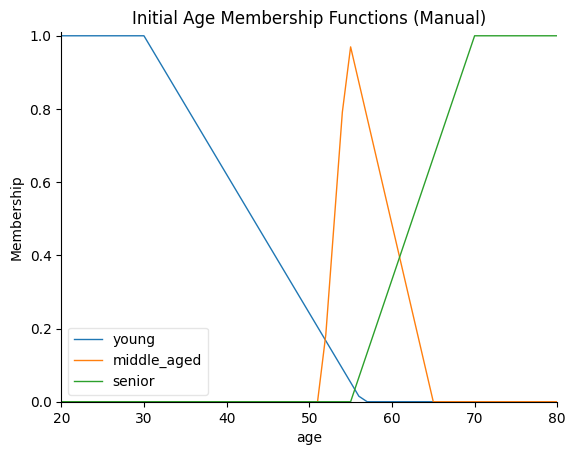

In [66]:
age.view()
plt.title('Initial Age Membership Functions (Manual)')
plt.show()

In [67]:
age['young'] = fuzz.trapmf(age.universe, [20, 20, 30, best_solution[0]])
age['middle_aged'] = fuzz.trimf(age.universe, [best_solution[0]-10, best_solution[1], 65])

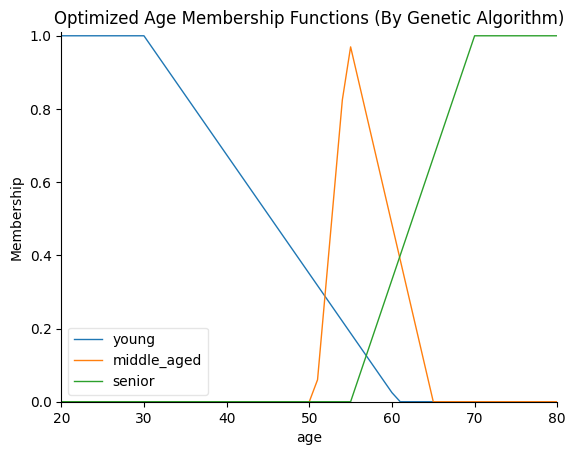

In [68]:
age.view()
plt.title('Optimized Age Membership Functions (By Genetic Algorithm)')
plt.show()

> Optimizing heart rate membership functions

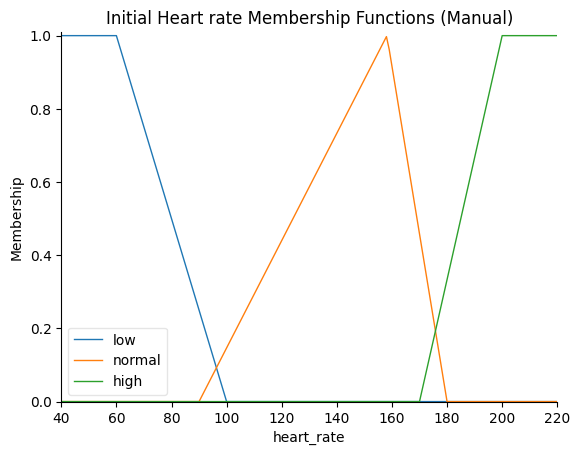

In [69]:
heart_rate.view()
plt.title('Initial Heart rate Membership Functions (Manual)')
plt.show()

In [70]:
heart_rate['normal'] = fuzz.trimf(heart_rate.universe, [95, best_solution[2], best_solution[2]+40])

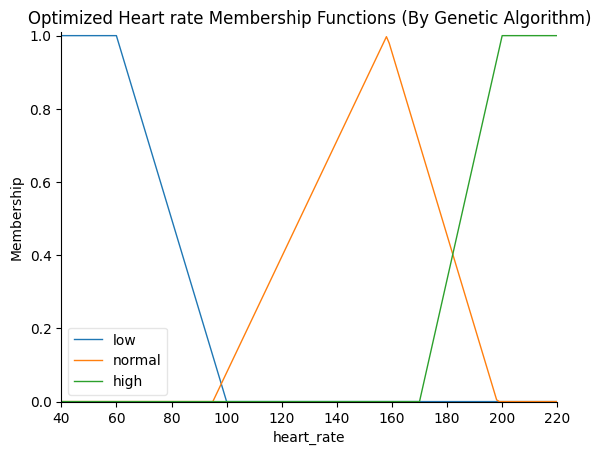

In [71]:
heart_rate.view()
plt.title('Optimized Heart rate Membership Functions (By Genetic Algorithm)')
plt.show()

> Optimizing risk membership functions

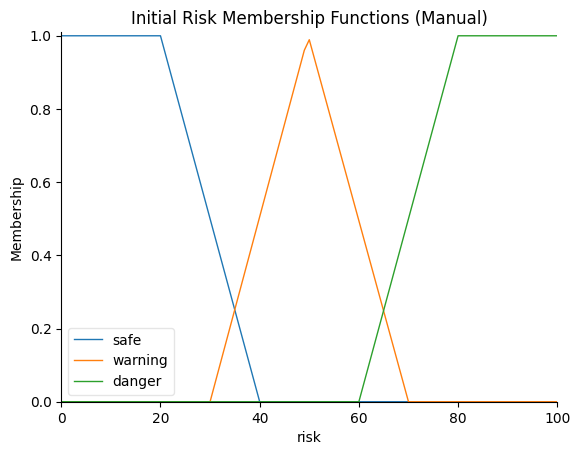

In [72]:
risk.view()
plt.title('Initial Risk Membership Functions (Manual)')
plt.show()

In [73]:
risk['warning'] = fuzz.trimf(risk.universe, [30, best_solution[3], 70])

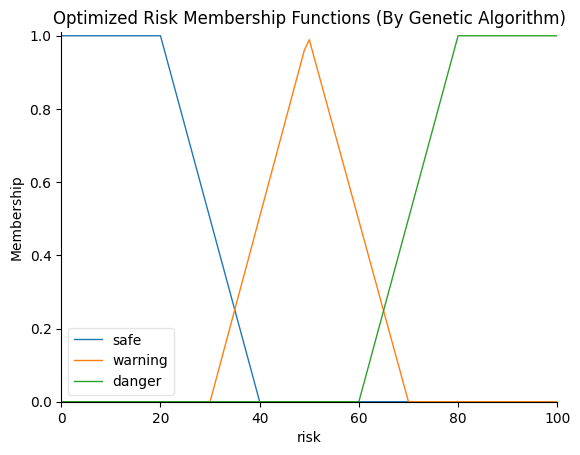

In [74]:
risk.view()
plt.title('Optimized Risk Membership Functions (By Genetic Algorithm)')
plt.show()

> Updating rules after optimazation

In [75]:
rules_updated = []

# Rules for High Risk (3 Rules)
rules_updated.append(ctrl.Rule(cluster['high_risk_zone'] | (age['senior'] & heart_rate['high']), risk['danger']))
rules_updated.append(ctrl.Rule(age['senior'] & heart_rate['low'], risk['danger']))
rules_updated.append(ctrl.Rule(cluster['high_risk_zone'] & heart_rate['normal'], risk['danger']))

# Rules for Medium Risk (3 Rules)
rules_updated.append(ctrl.Rule(age['middle_aged'] & (heart_rate['high'] | heart_rate['low']), risk['warning']))
rules_updated.append(ctrl.Rule(age['senior'] & heart_rate['normal'] & (cluster['low_risk_zone'] | cluster['med_risk_zone']), risk['warning']))
rules_updated.append(ctrl.Rule(age['young'] & heart_rate['high'], risk['warning']))

# Rules for Safe (3 Rules)
rules_updated.append(ctrl.Rule(age['young'] & heart_rate['normal'], risk['safe']))
rules_updated.append(ctrl.Rule(age['young'] & heart_rate['low'], risk['safe']))
rules_updated.append(ctrl.Rule(age['middle_aged'] & heart_rate['normal'] & (cluster['low_risk_zone'] | cluster['med_risk_zone']), risk['safe']))

> Creating optimized FIS

In [76]:
new_heart_risk_sys = ctrl.ControlSystem(rules_updated)
new_heart_risk_sim = ctrl.ControlSystemSimulation(new_heart_risk_sys)

In [77]:
# FIS function for implementation
def fuzzy_inference_system_optimized(cluster, age, heart_rate):
  # Set input values
  new_heart_risk_sim.input['cluster'] = cluster
  new_heart_risk_sim.input['age'] = age
  new_heart_risk_sim.input['heart_rate'] = heart_rate

  # Run simulator
  # Evaluate the control system
  new_heart_risk_sim.compute()

  # Get output value
  try:
        fuzzy_output = new_heart_risk_sim.output['risk']
  except KeyError:
        fuzzy_output = np.nan # Assign NaN if defuzzification fails(Safety step)
  return fuzzy_output

### Comparison Between Baseline and Optimized System

To evaluate the effectiveness of the Genetic Algorithm, a comparison was conducted between the initial (baseline) fuzzy inference system and the optimized system.

#### Before Optimization (Baseline System):
The fuzzy system was manually designed using predefined membership functions and rules. While it produced reasonable outputs, the system showed higher prediction error when compared to actual target values.

- Fitness Score: (put any early generation value or average)
- Performance: Moderate accuracy with less precise decision boundaries

#### After Optimization (Genetic Algorithm):
After applying the Genetic Algorithm, the membership functions were dynamically adjusted to better fit the data distribution.

- Best Fitness Score: 3.083723
- Performance: Improved accuracy and better alignment with actual risk levels

#### Conclusion:
The Genetic Algorithm significantly improved the performance of the fuzzy system by reducing prediction error and enhancing decision consistency. This demonstrates the effectiveness of evolutionary optimization in tuning fuzzy logic systems.

# Implementation

The system integrates preprocessing, clustering, fuzzy inference, and optimization into a unified pipeline.

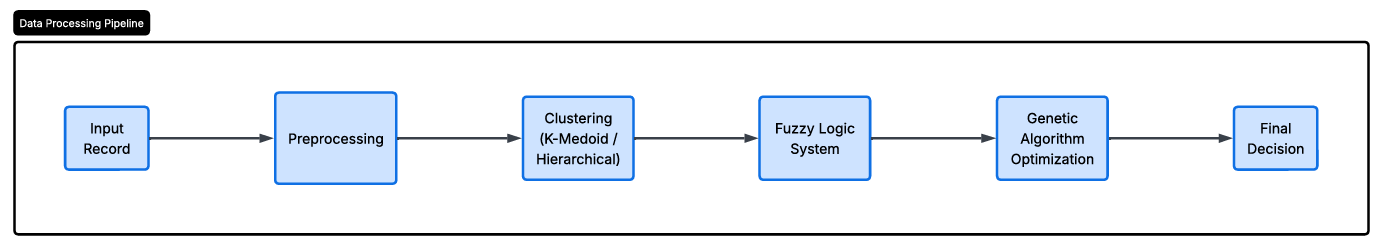

A new patient record is first preprocessed and scaled.

In [78]:
def preprocess_input(record, scaler, feature_columns):
    df_temp = pd.DataFrame([record])

    df_temp = df_temp[feature_columns]

    scaled = scaler.transform(df_temp)

    return scaled

Then assigned to a cluster using the K-Medoids model.

In [79]:
def predict_cluster(input_scaled, kmedoids_model):
    return kmedoids_model.predict(input_scaled)[0]

In [80]:
def decide(fuzzy_output):
    if fuzzy_output >= 70:
        return "DANGER RISK"
    elif fuzzy_output >= 40:
        return "WARNING RISK"
    else:
        return "SAFE RISK"

The cluster label, along with key health indicators such as age and heart rate, is passed to the fuzzy inference system to compute a risk percentage.Finally, a genetic algorithm-inspired adjustment is applied to convert the fuzzy output into a clear decision category (Safe, Warning, Danger Risk).

In [81]:
#pipeline
def full_system_pipeline(record):


    input_scaled = preprocess_input(
        record,
        scaler,
        features
    )

    cluster = predict_cluster(input_scaled, kmedoids)

    age = record['age']
    heart_rate = record['heartRate']

    fuzzy_output = fuzzy_inference_system_optimized(cluster, age, heart_rate)

    final_decision = decide(fuzzy_output)

    return {
        "Cluster": cluster,
        "Fuzzy Risk %": round(fuzzy_output, 2),
        "Final Decision": final_decision
    }

In [82]:
#Ex
sample = df_enc.iloc[0]

result = full_system_pipeline(sample)

result

{'Cluster': 2, 'Fuzzy Risk %': 59.82, 'Final Decision': 'WARNING RISK'}

## Conclusion

This project successfully combined multiple data mining techniques to build an intelligent healthcare decision system.

- EDA revealed key relationships between cardiovascular risk factors.
- Preprocessing improved data quality and model reliability.
- K-Medoids clustering identified meaningful patient groups.
- Hierarchical clustering validated clustering structure.
- The fuzzy logic system provided interpretable risk predictions.
- Genetic Algorithm optimization enhanced system performance.

Overall, the system can assist in early detection of cardiovascular risk, helping healthcare professionals make better decisions.

Future work could include:
- Using real-time patient data
- Adding more clinical features
- Testing with supervised models for comparison

# Key Findings & Business Impact

## 1. Exploratory Data Analysis (EDA)

###  Key Findings
- Most patients are middle-aged, indicating a naturally higher cardiovascular risk group.
- Strong positive correlation exists between systolic and diastolic blood pressure.
- Smoking, hypertension, and high glucose levels show noticeable association with heart disease cases.

###  Business / Research Value
- Confirms that cardiovascular risk is strongly driven by lifestyle and clinical indicators.
- Helps identify the most influential variables for early disease detection models.

###  Actions / Insights
- Focus screening programs on middle-aged and older individuals.
- Strengthen prevention campaigns targeting smoking and blood pressure control.
- Prioritize key correlated health indicators in predictive systems.



## 2. Data Preprocessing

###  Key Findings
- Missing values were present in multiple features and were successfully handled.
- Outliers were detected and capped using the IQR method.
- PCA reduced redundancy in highly correlated features (BP and Smoking).

###  Business / Research Value
- Improves data reliability and ensures more stable model performance.
- Reduces dimensionality while preserving most of the important variance.

### Actions / Insights
- Apply automated preprocessing pipelines in healthcare analytics systems.
- Reduce redundant clinical measurements in future dataset designs.
- Improve data collection quality at the source.


## 3. K-Medoids Clustering

###  Key Findings
- Optimal number of clusters = 3 (Low, Medium, High risk groups).
- High-risk cluster strongly associated with hypertension, high BMI, and older age.
- Clear separation between healthy and at-risk individuals.

###  Business / Research Value
- Enables unsupervised patient segmentation without requiring labels.
- Provides early identification of hidden risk groups.

### Actions / Insights
- Use clustering to automatically categorize patients in healthcare systems.
- Prioritize medical attention for high-risk cluster individuals.
- Support preventive healthcare strategies based on cluster membership.


## 4. Hierarchical Clustering

###  Key Findings
- Optimal clustering structure identified as 2 main clusters.
- Complete linkage provided the most meaningful separation.
- Cluster structure is consistent with K-Medoids findings.

###  Business / Research Value
- Validates the robustness of clustering structure from a hierarchical perspective.
- Helps understand relationships between patient groups at different levels.

###  Actions / Insights
- Can be used in triage systems for severity grouping.
- Supports hierarchical medical decision-making frameworks.


## 5. Fuzzy Logic System

### Key Findings
- The system successfully converts medical inputs into interpretable risk scores.
- Age, heart rate, and cluster label effectively determine risk level.
- Outputs are human-interpretable (Safe, Warning, Danger).

###  Business / Research Value
- Provides interpretable AI suitable for healthcare decision support.
- Bridges gap between data-driven models and medical reasoning.

###  Actions / Insights
- Integrate into clinical decision support systems.
- Use for early warning systems in hospitals and clinics.
- Assist doctors in fast risk assessment.


## 6. Genetic Algorithm Optimization

### Key Findings
- GA improved fuzzy system performance by optimizing membership functions.
- Fitness score increased and prediction error decreased.
- Better alignment between predicted and actual risk values.

### Business / Research Value
- Demonstrates effectiveness of evolutionary optimization in medical AI systems.
- Reduces manual tuning effort of fuzzy systems.

### Actions / Insights
- Apply GA for tuning healthcare models automatically.
- Extend optimization to other rule-based medical systems.
- Improve accuracy of decision-support tools.


## 7. Final Integrated System

### Key Findings
- Complete pipeline successfully integrates preprocessing, clustering, fuzzy logic, and GA.
- System provides final decision: Safe / Warning / Danger Risk.
- Combines interpretability with machine learning power.

### Business / Research Value
- Acts as a full intelligent decision support system for cardiovascular risk.
- Combines unsupervised learning and explainable AI.

### Actions / Insights
- Deploy in healthcare environments for early risk detection.
- Extend to real-time monitoring using wearable devices.
- Use as foundation for advanced clinical AI systems.


## Overall Insight
The proposed system successfully transforms raw medical data into an interpretable and optimized decision-making framework, enabling early detection of cardiovascular risks and supporting healthcare professionals in preventive care strategies.